# Advanced Mutual Fund Analytics

## Project Overview

This project focuses on analysing mutual fund data using Python, Pandas, NumPy, Matplotlib, and statistical techniques.

### Objectives

1. Calculate Historical Value at Risk (VaR) and Conditional Value at Risk (CVaR).
2. Analyse rolling 90-day Sharpe ratios.
3. Perform investor cohort analysis.
4. Evaluate SIP continuity and identify at-risk investors.
5. Build a simple risk-based mutual fund recommender.
6. Measure sector concentration using the Herfindahl-Hirschman Index (HHI).

### Dataset

The analysis uses historical NAV data, scheme performance, investor transactions, and portfolio holdings.

### Tools Used

- Python
- Pandas and NumPy
- Matplotlib
- Jupyter Notebook
- SQLite

In [1]:
import pandas as pd

# Load the VaR and CVaR report
var_report = pd.read_csv("var_cvar_report.csv")

# Display the 5 funds with the highest downside risk
print("HISTORICAL VaR AND CVaR ANALYSIS")
print("=" * 60)

display(
    var_report[
        ["scheme_name", "risk_grade", "VaR_95_pct", "CVaR_95_pct"]
    ].head(5)
)

HISTORICAL VaR AND CVaR ANALYSIS


,scheme_name,risk_grade,VaR_95_pct,CVaR_95_pct
0,SBI Small Cap Fund - Direct Plan - Growth,Very High,-2.6859,-3.2384
1,Axis Small Cap Fund - Regular - Growth,Very High,-2.6188,-3.1667
2,ABSL Small Cap Fund - Regular - Growth,Very High,-2.6021,-3.2459
3,Nippon India Small Cap Fund - Regular - Growth,Very High,-2.5438,-3.2304
4,SBI Small Cap Fund - Regular Plan - Growth,Very High,-2.4507,-3.0595


ROLLING 90-DAY SHARPE RATIO ANALYSIS


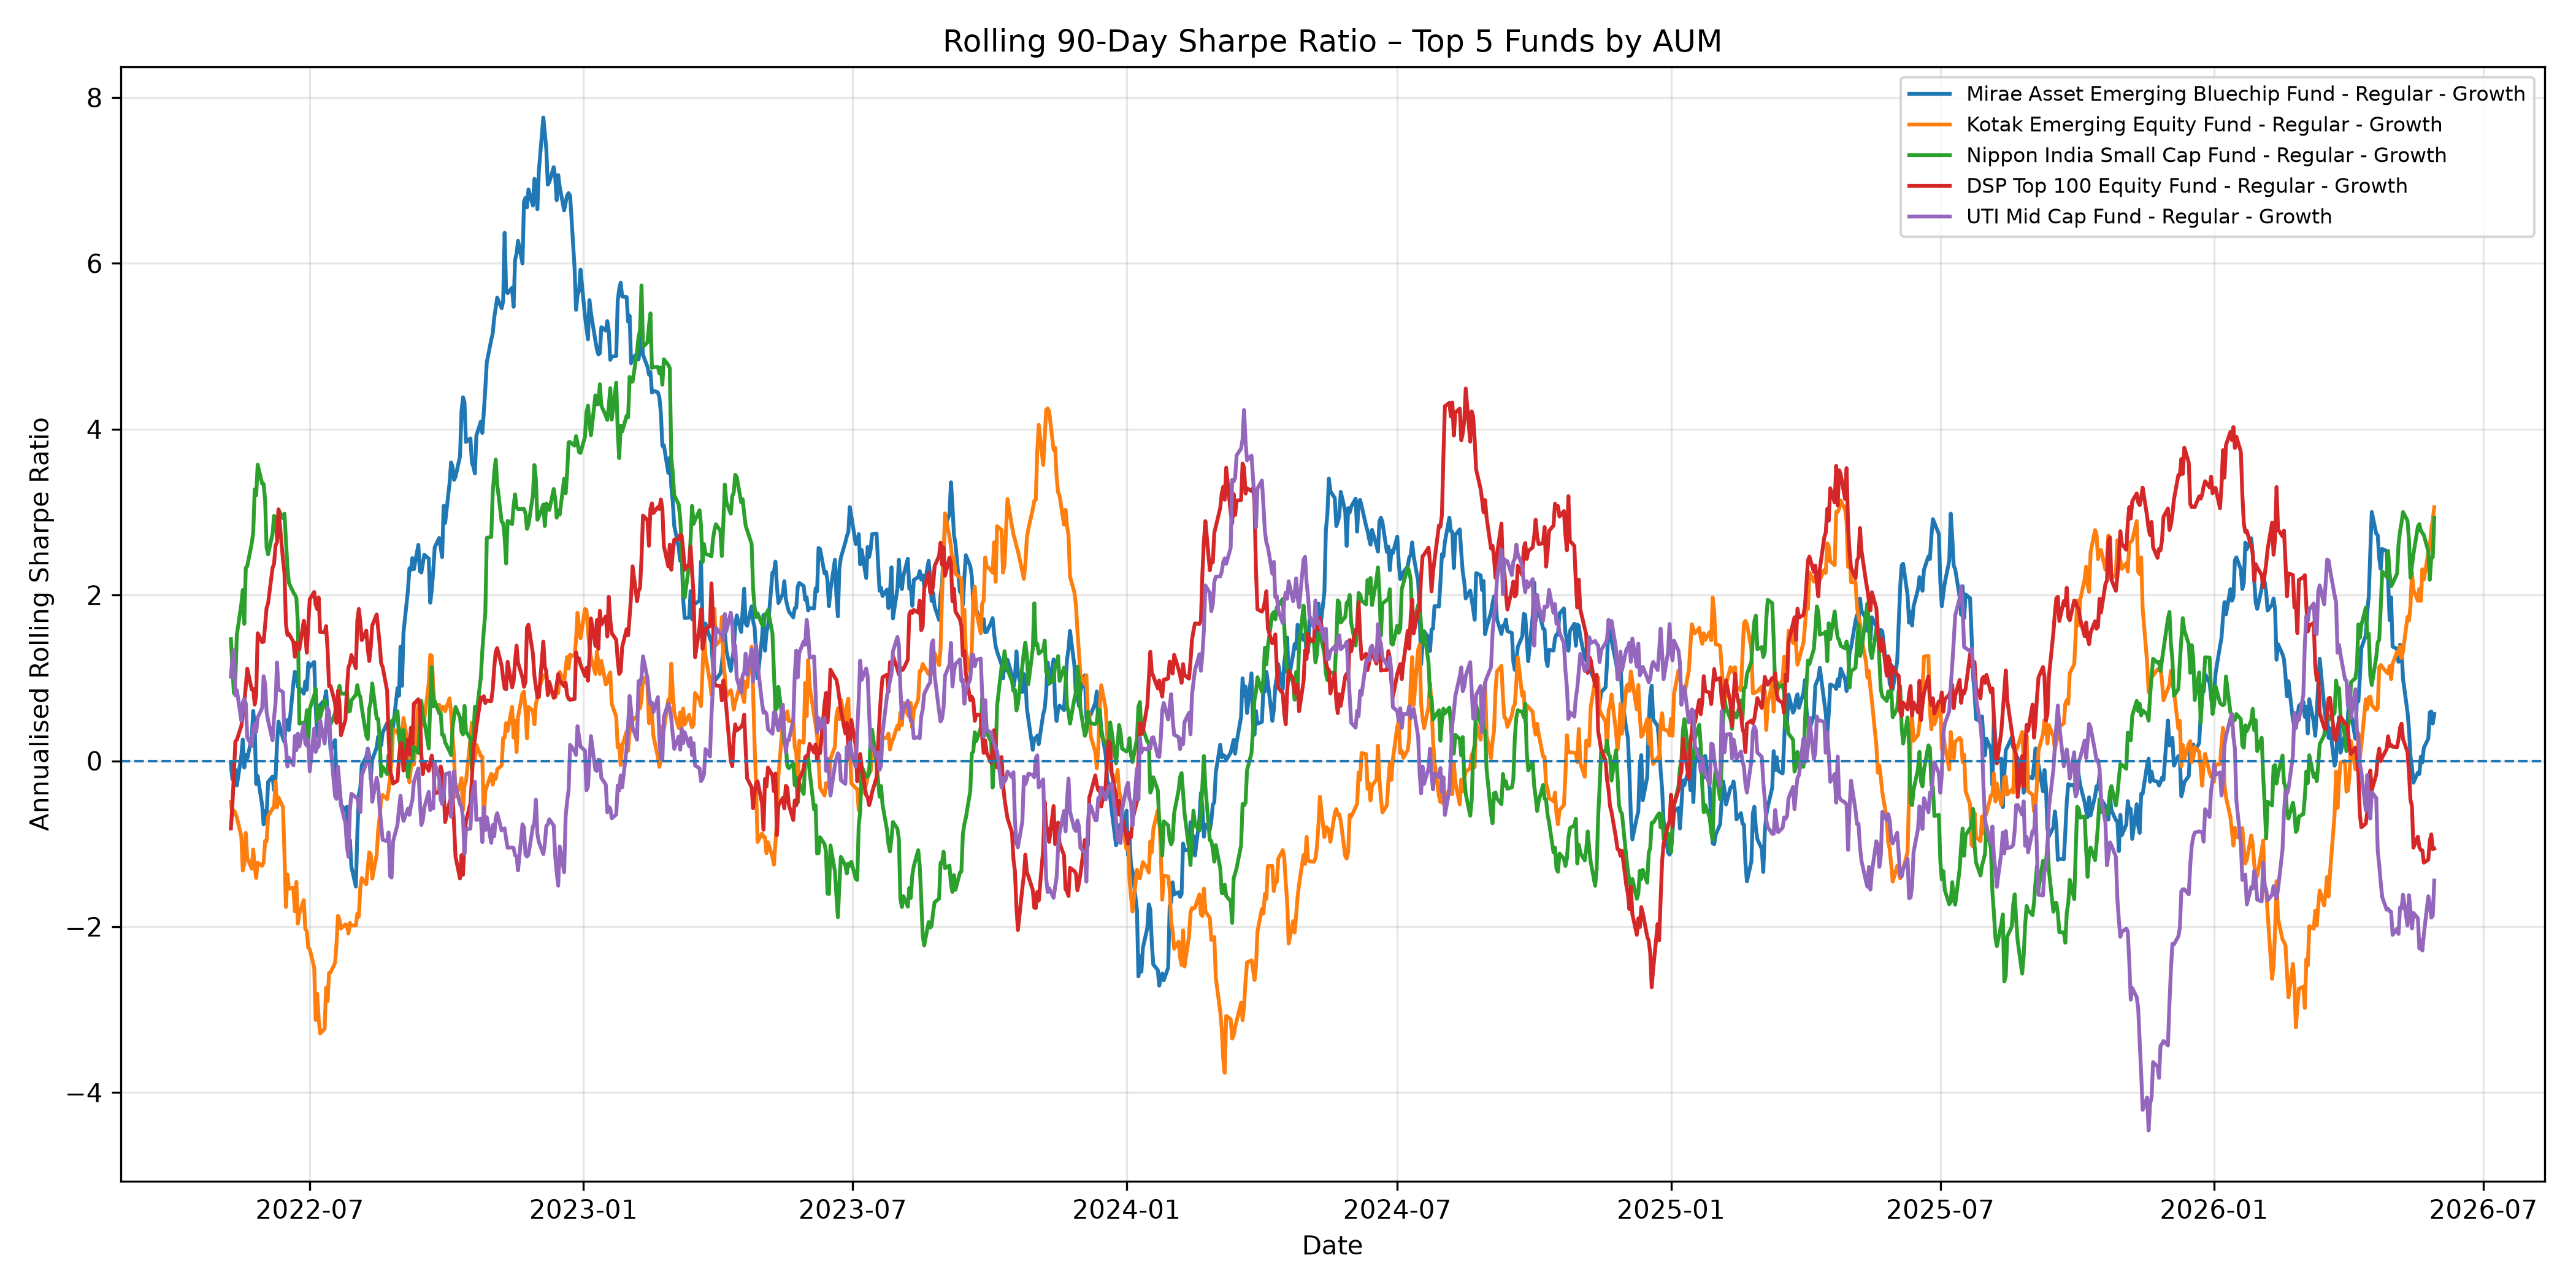

In [2]:
from IPython.display import Image, display

print("ROLLING 90-DAY SHARPE RATIO ANALYSIS")

display(Image(filename="rolling_sharpe_chart.png"))


In [3]:
import pandas as pd

# Load investor cohort report
cohort_report = pd.read_csv("investor_cohort_report.csv")

print("INVESTOR COHORT ANALYSIS")
print("=" * 60)

display(cohort_report)

INVESTOR COHORT ANALYSIS


,cohort_year,investor_count,avg_sip_amount_inr,total_invested_inr,top_preferred_amfi_code,top_fund_transaction_count,scheme_name
0,2024,4803,10996.885825,2258062304,125498,752,HDFC Mid-Cap Opportunities Fund - Direct - Growth
1,2025,197,13505.209581,18992635,119599,11,SBI Small Cap Fund - Direct Plan - Growth


In [4]:
import pandas as pd

# Load SIP continuity report
sip_report = pd.read_csv("sip_continuity_report.csv")

print("SIP CONTINUITY ANALYSIS")
print("=" * 60)

print("Total eligible investors:", len(sip_report))

print("\nContinuity status:")
print(sip_report["continuity_status"].value_counts())

print("\nTop 10 investors with largest average SIP gaps:")
display(
    sip_report.sort_values(
        "avg_gap_days", ascending=False
    ).head(10)
)

SIP CONTINUITY ANALYSIS
Total eligible investors: 1362

Continuity status:
continuity_status
At-Risk    1332
Regular      30
Name: count, dtype: int64

Top 10 investors with largest average SIP gaps:


,investor_id,sip_transactions,avg_gap_days,max_gap_days,continuity_status
0,INV001890,6,102.6,207,At-Risk
1,INV001156,6,102.4,175,At-Risk
2,INV004296,6,102.2,304,At-Risk
3,INV003325,6,101.0,155,At-Risk
4,INV000522,6,100.8,309,At-Risk
5,INV000608,6,100.2,324,At-Risk
6,INV001883,6,99.2,203,At-Risk
7,INV002166,6,99.2,248,At-Risk
8,INV001367,6,99.0,222,At-Risk
9,INV001491,6,98.8,260,At-Risk


In [5]:
import pandas as pd

performance = pd.read_csv("data/processed/07_scheme_performance.csv")

risk_groups = {
    "Low": ["Low"],
    "Moderate": ["Moderate", "Moderately High"],
    "High": ["High", "Very High"]
}

for appetite, grades in risk_groups.items():
    recommendations = (
        performance[performance["risk_grade"].isin(grades)]
        .sort_values("sharpe_ratio", ascending=False)
        .head(3)
    )

    print(f"\n{appetite.upper()} RISK RECOMMENDATIONS")
    display(
        recommendations[
            ["scheme_name", "risk_grade", "sharpe_ratio",
             "return_3yr_pct", "expense_ratio_pct"]
        ]
    )
    


LOW RISK RECOMMENDATIONS


,scheme_name,risk_grade,sharpe_ratio,return_3yr_pct,expense_ratio_pct
14,ICICI Pru Liquid Fund - Regular - Growth,Low,7.68,7.68,0.74
23,Kotak Liquid Fund - Regular - Growth,Low,6.18,6.18,0.60
30,ABSL Liquid Fund - Regular - Growth,Low,5.14,5.14,0.79



MODERATE RISK RECOMMENDATIONS


,scheme_name,risk_grade,sharpe_ratio,return_3yr_pct,expense_ratio_pct
5,HDFC Top 100 Fund - Regular Plan - Growth,Moderate,1.06,14.84,1.55
34,Mirae Asset Large Cap Fund - Regular - Growth,Moderate,1.06,14.81,1.46
11,ICICI Pru Bluechip Fund - Direct - Growth,Moderate,1.03,14.41,0.80



HIGH RISK RECOMMENDATIONS


,scheme_name,risk_grade,sharpe_ratio,return_3yr_pct,expense_ratio_pct
21,Kotak Emerging Equity Fund - Regular - Growth,High,0.96,18.23,1.56
12,ICICI Pru Midcap Fund - Regular - Growth,High,0.95,18.08,1.36
2,SBI Small Cap Fund - Regular Plan - Growth,Very High,0.94,23.39,1.43


In [6]:
import pandas as pd

# Load sector HHI report
hhi_report = pd.read_csv("sector_hhi_report.csv")

print("SECTOR HHI CONCENTRATION ANALYSIS")
print("=" * 60)

print("\nConcentration level distribution:")
print(hhi_report["concentration_level"].value_counts())

print("\nTOP 5 MOST CONCENTRATED FUNDS")
display(
    hhi_report[
        ["scheme_name", "category", "HHI", "concentration_level"]
    ].head(5)
)

print("\nTOP 5 MOST DIVERSIFIED FUNDS")
display(
    hhi_report.sort_values("HHI")[
        ["scheme_name", "category", "HHI", "concentration_level"]
    ].head(5)
)

SECTOR HHI CONCENTRATION ANALYSIS

Concentration level distribution:
concentration_level
Moderate    27
High         4
Low          3
Name: count, dtype: int64

TOP 5 MOST CONCENTRATED FUNDS


,scheme_name,category,HHI,concentration_level
0,Axis Bluechip Fund - Regular - Growth,Large Cap,0.296828,High
1,Mirae Asset Tax Saver Fund - Regular - Growth,ELSS,0.255094,High
2,HDFC Mid-Cap Opportunities Fund - Direct - Growth,Mid Cap,0.253155,High
3,UTI Flexi Cap Fund - Regular - Growth,Flexi Cap,0.251332,High
4,DSP Midcap Fund - Regular - Growth,Mid Cap,0.241077,Moderate



TOP 5 MOST DIVERSIFIED FUNDS


,scheme_name,category,HHI,concentration_level
33,UTI Mid Cap Fund - Regular - Growth,Mid Cap,0.124070,Low
32,Kotak Flexicap Fund - Regular - Growth,Flexi Cap,0.136206,Low
31,SBI Bluechip Fund - Regular Plan - Growth,Large Cap,0.142491,Low
30,Axis Small Cap Fund - Regular - Growth,Small Cap,0.159614,Moderate
29,Nippon India Small Cap Fund - Regular - Growth,Small Cap,0.160299,Moderate


# Overall Findings and Conclusion

The Day 3 advanced analytics project examined mutual fund risk, performance, investor behaviour, and portfolio concentration.

### Key Findings

1. Small-cap funds showed higher historical downside risk in the VaR and CVaR analysis.
2. The 2024 investor cohort contributed the largest total investment.
3. SIP continuity analysis identified 1,332 potentially at-risk investors.
4. The risk-based recommender ranked funds using historical Sharpe ratios.
5. Sector HHI analysis showed that most analysed equity funds had moderate concentration.

### Conclusion

The project demonstrates how Python-based data analytics can help analyse mutual fund performance, understand investor behaviour, identify potential risks, and compare portfolio concentration.

The results are based on historical datasets and should not be treated as predictions of future performance.